# 03 · Which championship is more competitive?

"Competitive" can mean several things, so we measure four of them for every season of both
series and test the race-level ones statistically:

| measure | level | what it captures |
|---|---|---|
| Qualifying spread, pole to P10 (%) | race | how close the *machinery* is over one lap |
| Winning margin (% of race time) | race | how close the *race* is at the flag |
| Different race winners | season | how many people can win |
| Points Gini (regular starters) | season | how evenly success is spread |

Percentages make the series comparable, since an F1 race lasts about 90 minutes and a MotoGP
race about 40. Wet qualifying sessions and abnormally short races are excluded (see
`analysis.race_summaries`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1_vs_motogp import plots
from f1_vs_motogp.analysis import compare_series, season_parity
from f1_vs_motogp.config import DATA_PROCESSED
from f1_vs_motogp.data import load_tables

plots.apply_style()
t = load_tables()
summary = pd.read_parquet(DATA_PROCESSED / "race_summary.parquet")
parity = season_parity(t, summary)
parity.to_csv(DATA_PROCESSED / "season_parity.csv", index=False)

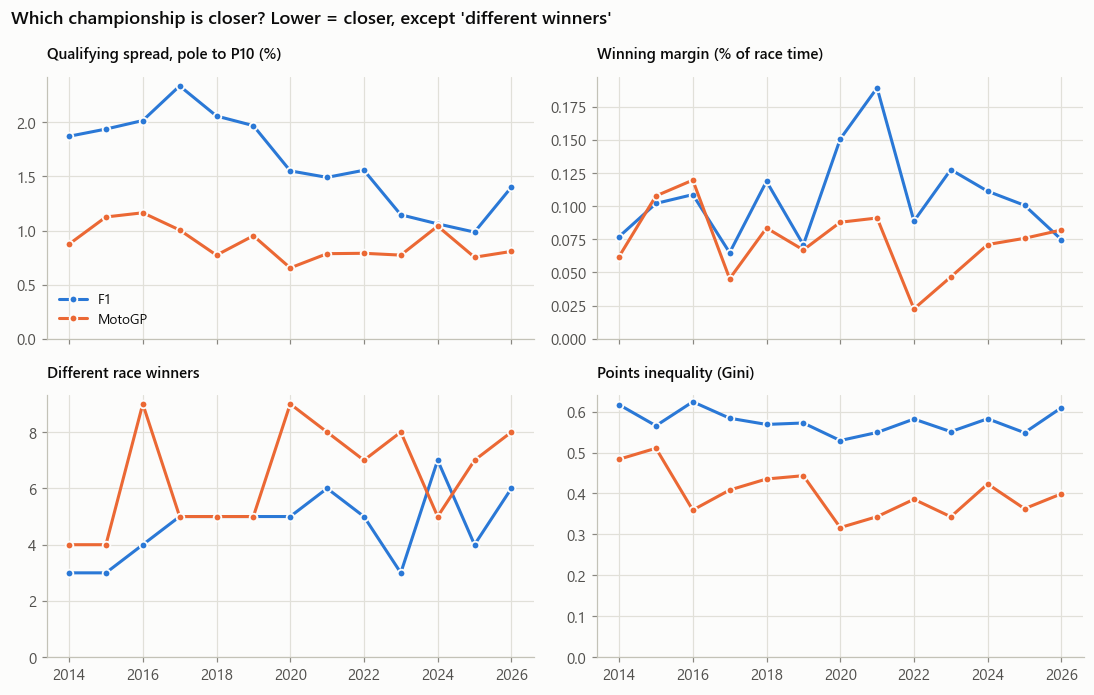

In [2]:
fig = plots.parity_panels(parity)
plots.save(fig, "parity_panels")
plt.show()

In [3]:
parity.groupby("series")[["distinct_winners", "top_winner_share", "points_gini",
                          "title_margin_pct", "median_quali_spread_pct",
                          "median_margin_pct"]].mean().T.round(3)

series,F1,MotoGP
distinct_winners,4.692,6.462
top_winner_share,0.530,0.420
points_gini,0.575,0.401
title_margin_pct,19.438,13.681
median_quali_spread_pct,1.645,0.884
median_margin_pct,0.107,0.074


## Statistical comparison

For the race-level measures, we bootstrap the difference in medians (F1 − MotoGP, 5,000
resamples of races). We do this for the whole period and for the current F1 ground-effect era
(2022+), when F1's field compressed.

In [4]:
cmp = pd.concat([
    compare_series(summary).assign(period="2014-2026"),
    compare_series(summary, since=2022).assign(period="2022-2026"),
], ignore_index=True)
cmp.to_csv(DATA_PROCESSED / "series_comparison.csv", index=False)
cmp.round(3)

,measure,f1_median,motogp_median,diff_f1_minus_motogp,ci_low,ci_high,n_f1,n_motogp,period
0,"Qualifying spread, pole to P10 (%)",1.596,0.835,0.762,0.644,0.870,255,224,2014-2026
1,Winning margin (% of race time),0.109,0.078,0.031,0.007,0.055,271,240,2014-2026
2,"Qualifying spread, pole to P10 (%)",1.189,0.806,0.382,0.269,0.504,104,96,2022-2026
3,Winning margin (% of race time),0.106,0.070,0.036,0.004,0.078,112,100,2022-2026


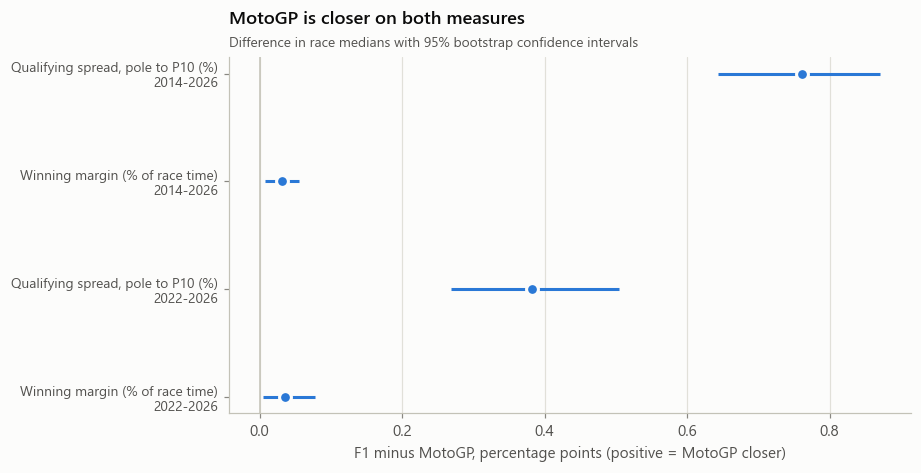

In [5]:
fig = plots.bootstrap_forest(cmp)
plots.save(fig, "bootstrap_comparison")
plt.show()

## Verdict

* **Qualifying is much tighter in MotoGP.** Across 2014–2026 the median pole-to-P10 gap is
  roughly half that of F1, and the bootstrap interval for the difference is far from zero. F1
  has closed much of the gap: its pole-to-P10 spread fell from about 2 % in 2014–2019 to
  1.0–1.4 % since 2023. MotoGP is still tighter in the current era.
* **Races are closer at the flag in MotoGP**, though the difference is smaller and noisier
  (its interval sits just above zero).
* **More riders win, and points are spread more evenly, in MotoGP.** It had at least as many
  different winners as F1 in 12 of 13 seasons (2024 is the exception) and a lower points Gini
  in every season.

Caveats: the field sizes and points systems differ (MotoGP pays the top 15 with
25-20-16-13-11..., F1 the top 10 with 25-18-15-12-10...). Both affect the Gini, so the
winners and spread measures are the cleaner comparison. Season-level measures are also
driven by individual dynasties (Mercedes 2014–2020, Verstappen 2023, Márquez 2014 and 2019).